C:\Users\A040699\AppData\Roaming\Python\Python310\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\A040699\AppData\Roaming\Python\Python310\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\A040699\AppData\Roaming\Python\Python310\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\A040699\AppData\Roaming\Python\Python310\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A colu

[2 1 0]


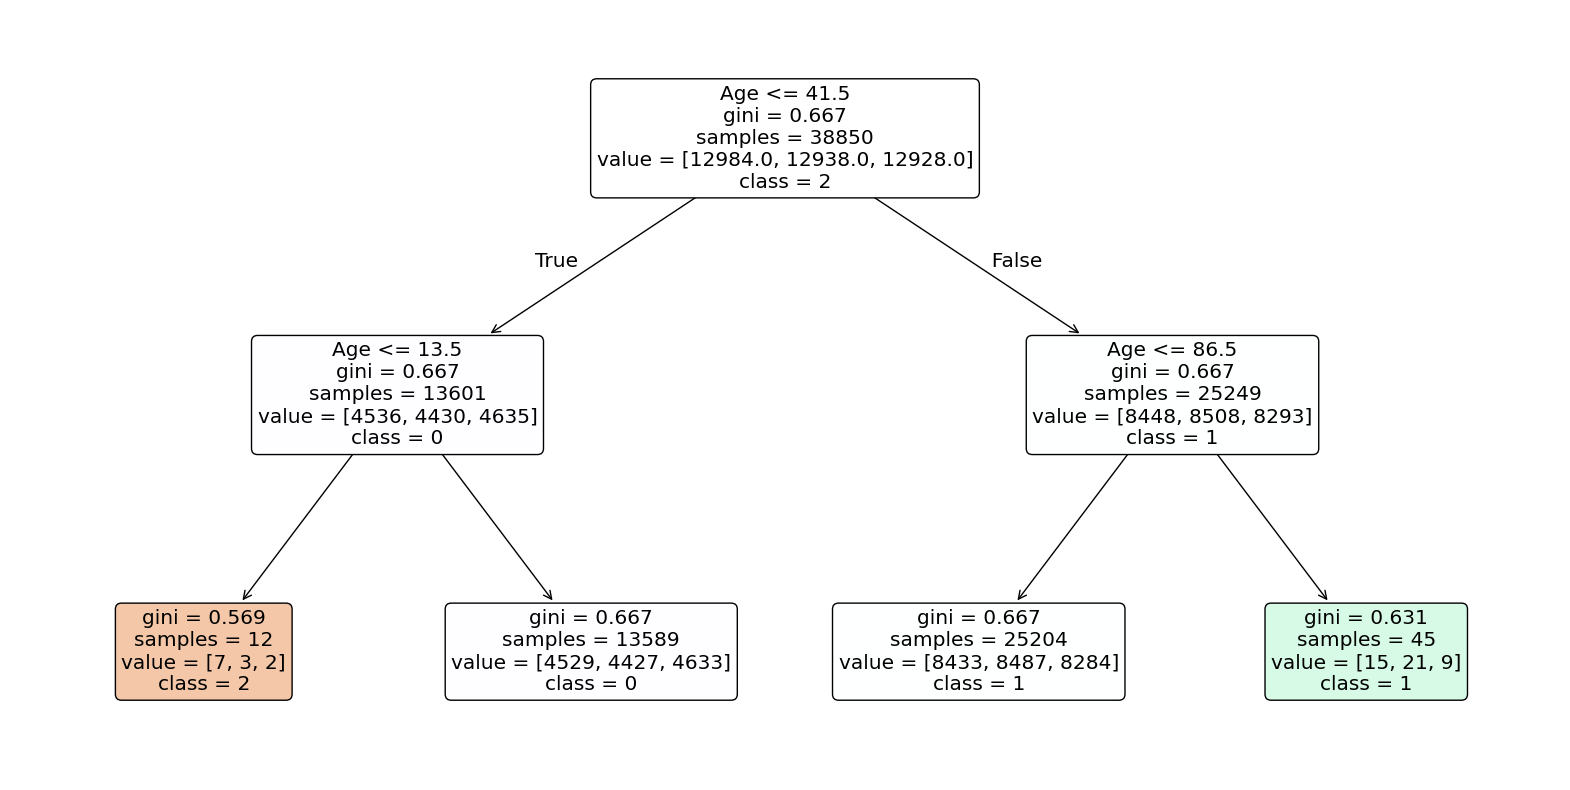

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.metrics import r2_score,mean_squared_error,root_mean_squared_error,mean_absolute_error,f1_score,classification_report,accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
import matplotlib.pyplot as plt


# load data
# hrdf= pd.read_csv('HR_Attrition_Clean.csv')

hdf= pd.read_csv('HealthcareClean.csv')

#use label encoder to convert categorical data into numerical data
label = LabelEncoder()
# label.fit_transform(hdf[['Gender']])
hdf['Gender'] = label.fit_transform(hdf[['Gender']])
hdf['Admission Type'] = label.fit_transform(hdf[['Admission Type']])
hdf['Test Results'] = label.fit_transform(hdf[['Test Results']])
print(hdf['Test Results'].unique())
hdf['Medication'] = label.fit_transform(hdf[['Medication']])

# load transformed data into X and Y
# X = hrdf[['YearsAtCompany','JobSatisfaction','WorkLifeBalance']] # find the correlation between the features and target variable and select the features first
# i.e. YearsAtCompany, JobSatisfaction, WorkLifeBalance through correlation matrix or heat map and then select the features for X
# Y = hrdf['Attrition']

X = hdf[['Age','Gender','Admission Type','Medication']]

Y = hdf['Test Results']

# split into train and test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.7, random_state=42)

# train the model on tranied data 
model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train, Y_train)

#predict the model on test data
predictions = model.predict(X_test)

# check the r2 score or metrics 

# print("R2 score :", r2_score(Y_test,predictions))
# print("Mean squared error:", mean_squared_error(Y_test,predictions))
# print("Root mean squared error:", root_mean_squared_error(Y_test,predictions))
# print("Mean absolute error:", mean_absolute_error(Y_test,predictions))

# f1_score(Y_test, predictions, average='weighted')
# print("F1 Score:", f1_score(Y_test, predictions, average='weighted'))

# classification_report(Y_test, predictions)
# print("Classification Report:\n",classification_report(Y_test, predictions))

# accuracy_score(Y_test, predictions)
# print("Accuracy Score:", accuracy_score(Y_test, predictions))

# visualize the decision tree
plt.figure(figsize=(20,10))
tree.plot_tree(model, filled=True, feature_names=X.columns,class_names=['2','1','0'], rounded=True)
plt.show()


In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score,classification_report,accuracy_score,r2_score
from sklearn.preprocessing import StandardScaler
from sklearn import tree
import matplotlib.pyplot as plt

# load data

cdf= pd.read_csv('Credit.csv')
cdf.info()
cdf.shape

# load transformed data into X and Y


X = cdf[['RevolvingUtiOfUnsecuredLoans','DebtRatio','age','MonthlyIncome','NoRealEstateLoansOrLines','NoofTime30_59DaysPastDue',
         'NoofTime30_59DaysPastDue', 'NoOfTime60_89DaysPastDue']]

Y = cdf['Credit']

# split into train and test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.7, random_state=42)

# train the model on tranied data 
model = DecisionTreeClassifier(max_depth=10,min_samples_split=10,min_samples_leaf=12, random_state=42)
model.fit(X_train, Y_train)

#predict the model on test data
predictions = model.predict(X_test)

# check the r2 score or metrics 

print("R2 score :", r2_score(Y_test,predictions))


f1_score(Y_test, predictions, average='weighted')
print("F1 Score:", f1_score(Y_test, predictions, average='weighted'))

classification_report(Y_test, predictions)
print("Classification Report:\n",classification_report(Y_test, predictions))

print("Accuracy Score:", accuracy_score(Y_test, predictions))

# visualize the decision tree
# plt.figure(figsize=(20,10))
# tree.plot_tree(model, filled=True, feature_names=X.columns,rounded=True)
# plt.show()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8026 entries, 0 to 8025
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Credit                        8026 non-null   int64  
 1   RevolvingUtiOfUnsecuredLoans  8026 non-null   float64
 2   age                           8026 non-null   int64  
 3   DebtRatio                     8026 non-null   float64
 4   MonthlyIncome                 8026 non-null   int64  
 5   NoOfDependents                8026 non-null   int64  
 6   NoRealEstateLoansOrLines      8026 non-null   int64  
 7   NoOfOpenCreditLinesAndLoans   8026 non-null   int64  
 8   NoofTime30_59DaysPastDue      8026 non-null   int64  
 9   NoOfTime60_89DaysPastDue      8026 non-null   int64  
 10  NorOfTimes90DaysLate          8026 non-null   int64  
dtypes: float64(2), int64(9)
memory usage: 689.9 KB
R2 score : -0.22922974973921217
F1 Score: 0.9190310347287541
Classificatio